# Exercise 7. Underfitting, Overfitting and Regularization methods

Underfitting, Overfitting and Regularization methods



(1000, 2) (1000,)


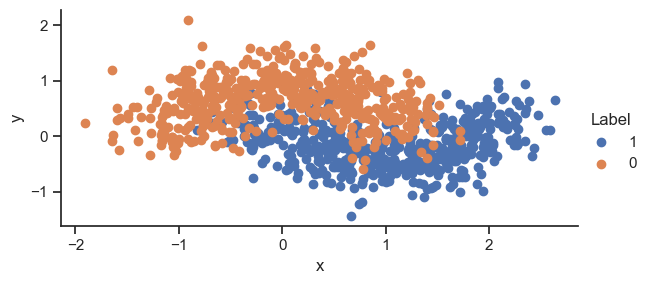

In [1]:
# Generate dataset which will be used to demonstrate underfitting or overfitting 
from sklearn.datasets import make_moons
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# tf.keras.backend.set_floatx('float64')  # commented out to avoid a float64/float32 error with the L1 regularizer

sns.set(style='ticks')

dots,labels = make_moons(n_samples=1000, noise=0.30, random_state=1)
print(dots.shape,labels.shape)
df = pd.DataFrame(data={'x':dots[:,0], 'y':dots[:,1], 'Label':labels})

# Copied from: https://stackoverflow.com/questions/14885895/color-by-column-values-in-matplotlib
fig = sns.FacetGrid(data=df, hue='Label', hue_order=df['Label'].unique(), aspect=2)
fig.map(plt.scatter, 'x', 'y').add_legend()

/Users/dineshbisht/masterdegree/myproject_env/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


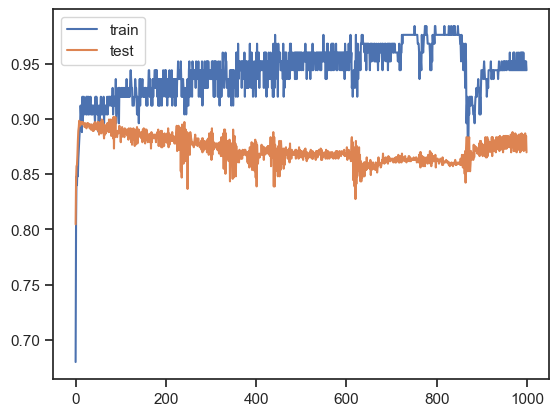

In [2]:
tf.keras.utils.set_random_seed(1) # to make the results reproducible

# Splitting the dataset
train_X, train_y = dots[:len(dots) // 8, :], labels[:len(dots) // 8]
test_X, test_y = dots[len(dots) // 8:, :], labels[len(dots) // 8:]
# Create simple neural network
model_overfit = tf.keras.Sequential([
    tf.keras.layers.Dense(500,activation='relu',input_shape=(2,)),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
opt = tf.keras.optimizers.Adam(learning_rate=0.1)
model_overfit.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])
# Define validation set in order to accuracy can be recorder 
history_overfit = model_overfit.fit(train_X,
                train_y,
                validation_data = (test_X,test_y),
                batch_size = 2**5,
                epochs=1000,
                verbose=0)
# Plot the accucary and validation accuracy
plt.plot(history_overfit.history['accuracy'],label='train')
plt.plot(history_overfit.history['val_accuracy'],label='test')
plt.legend()
plt.show()

Explain the above figure?

__Answer here!!!__

The figure shows the accuracy of the model on the training and test datasets during 1000 epochs.

At the beginning both accuracies rise quickly close to .80 but After that the training accuracy
keeps going up and stays around 0.93 to 0.95, but the test accuracy goes down a little and stays
around 0.86 to 0.87. The two lines separate and do not come back together. This is overfitting as
the model learns the training data, including its noise, but does not work as well on new data ie test data.

The reason is that the network is very large (500 hidden nodes) and the training set is very small (only 125 samples). The model has enough freedom to memorize the training points instead of learning the general shape of the two moons.

The lines are also very jagged. This is probably because the learning rate (0.1) is high, so the
weights change a lot at every step.

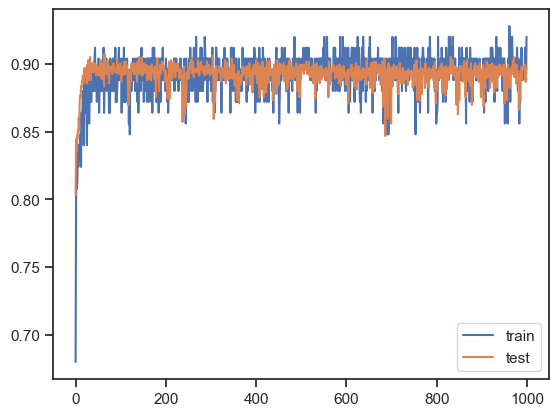

In [4]:
## L2 Regularization
## Use exactly same NN but add L2 Regularization

tf.keras.utils.set_random_seed(1) # to make the results reproducible

model_l2 = tf.keras.Sequential([
    tf.keras.layers.Dense(500,activation='relu',input_shape=(2,),kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
opt = tf.keras.optimizers.Adam(learning_rate=0.1)
model_l2.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])
history_l2 = model_l2.fit(train_X,
                train_y,
                validation_data = (test_X,test_y),
                batch_size = 2**5,
                epochs=1000,
                verbose=0)

# Plot the accucary and validation accuracy
plt.plot(history_l2.history['accuracy'],label='train')
plt.plot(history_l2.history['val_accuracy'],label='test')
plt.legend()
plt.show()

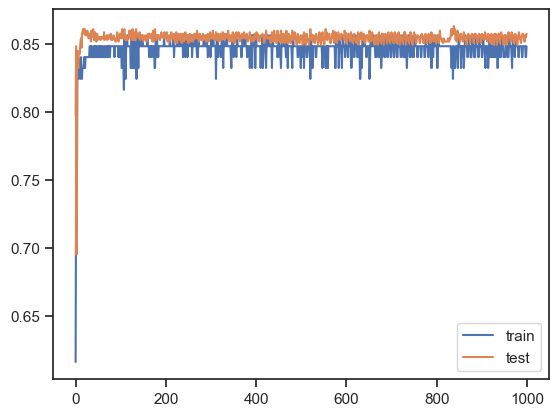

In [5]:
## L1 Regularization
## Use exactly same NN but add L1 Regularization

tf.keras.utils.set_random_seed(1) # to make the results reproducible

model_l1 = tf.keras.Sequential([
    tf.keras.layers.Dense(500,activation='relu',input_shape=(2,),kernel_regularizer=tf.keras.regularizers.l1(0.01)),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
opt = tf.keras.optimizers.Adam(learning_rate=0.1)
model_l1.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])
history_l1 = model_l1.fit(train_X,
                train_y,
                validation_data = (test_X,test_y),
                batch_size = 2**5,
                epochs=1000,
                verbose=0)

# Plot the accucary and validation accuracy
plt.plot(history_l1.history['accuracy'],label='train')
plt.plot(history_l1.history['val_accuracy'],label='test')
plt.legend()
plt.show()

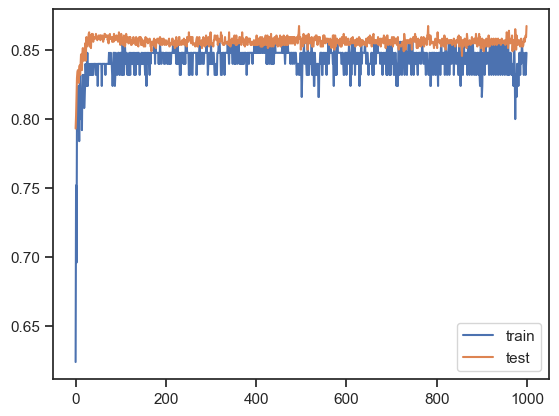

In [ ]:
## L1_L2 Regularization
## Use exactly same NN but add L1 and L2 Regularization

tf.keras.utils.set_random_seed(1) # to make the results reproducible

model_l1_l2 = tf.keras.Sequential([
    tf.keras.layers.Dense(500,activation='relu',input_shape=(2,),kernel_regularizer=tf.keras.regularizers.l1_l2(l1=0.01,l2=0.01)),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
opt = tf.keras.optimizers.Adam(learning_rate=0.1)
model_l1_l2.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])
history_l1_l2 = model_l1_l2.fit(train_X,
                train_y,
                validation_data = (test_X,test_y),
                batch_size = 2**5,
                epochs=1000,
                verbose=0)

# Plot the accucary and validation accuracy
plt.plot(history_l1_l2.history['accuracy'],label='train')
plt.plot(history_l1_l2.history['val_accuracy'],label='test')
plt.legend()
plt.show()

In [ ]:
# Dropout
## Use exactly same NN but add Dropout Regularization

tf.keras.utils.set_random_seed(1) # to make the results reproducible

model_dropout = tf.keras.Sequential([
    tf.keras.layers.Dense(500,activation='relu',input_shape=(2,)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
opt = tf.keras.optimizers.Adam(learning_rate=0.1)
model_dropout.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])
history_dropout = model_dropout.fit(train_X,
                train_y,
                validation_data = (test_X,test_y),
                batch_size = 2**5,
                epochs=1000,
                verbose=0)

# Plot the accucary and validation accuracy
plt.plot(history_dropout.history['accuracy'],label='train')
plt.plot(history_dropout.history['val_accuracy'],label='test')
plt.legend()
plt.show()



# Conclusion

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing them__

Write conclusion about results of used regularization methods

